In [21]:
#####     Model Bias Analysis (2)     #####
# Carbon cycle process based analysis

from pathlib import Path
from string import ascii_lowercase
import warnings

import numpy as np
import pandas as pd
from joblib import load
import rasterio

import matplotlib.pyplot as plt
from statsmodels.nonparametric.smoothers_lowess import lowess

ROOT = Path("./")
DataDir = ROOT / "Data"

SECONDS_PER_YEAR = 365 * 24 * 60 * 60

def flipImage(tiff: np.ndarray) -> np.ndarray:
    """Flip latitude and shift longitude from original raster layout to 0-360 lon layout."""
    tiff = np.flip(tiff, axis=0)
    temp = np.zeros_like(tiff)
    temp[:, :180] = tiff[:, 180:]
    temp[:, 180:] = tiff[:, :180]
    return temp

def panel_label(ax, label: str):
    ax.text(
        0.03, 0.98, f"({label})",
        transform=ax.transAxes, ha="left", va="top",
        fontsize=11, fontweight="bold", zorder=10,
        bbox=dict(facecolor="white", edgecolor="none", alpha=0.65, pad=1.0),
    )


In [22]:
### ----- Load Data ----- ###
ESAv7_data = np.load(DataDir / "AGBC_ESAv7.npz")
ESAv7_data = {k.title(): flipImage(v.astype(np.float32)) for k, v in ESAv7_data.items()}
ESA_data = ESAv7_data["Mean"].copy()

CMIP_set = np.load(DataDir / "CMIP6_AGBC.npz")
modelNames = list(CMIP_set.keys())
CMIP_data = np.stack([np.array(CMIP_set[name], dtype=np.float32) for name in modelNames], axis=0)
modelNum = len(modelNames)
print(f"CMIP Models: {modelNum}\n")

CMIP_raw = load(DataDir / "CMIP6_raw.joblib")
CMIP_sup = load(DataDir / "CMIP6_sup.joblib")

with rasterio.open(DataDir / "Koppen_2010.tif", "r") as src:
    Koppen = flipImage(src.read(1).astype(np.float32))

ValidMask = (Koppen > 0) & (ESA_data > 0)
TreeMask = load(DataDir / "Masks" / "treemask.joblib").astype(bool)
TreeMask &= ValidMask

ESA_datat = ESA_data.copy()
ESA_datat[~TreeMask] = np.nan
CMIP_datat = CMIP_data.copy()
CMIP_datat[:, ~TreeMask] = np.nan

cluster_df = pd.read_csv(ROOT / "cluster.csv", header=0)
cluster_df["Cluster"] = cluster_df["Cluster"].astype(int)
cluster_map = cluster_df.set_index("Model")["Cluster"].to_dict()
cluster_ids = sorted(cluster_df["Cluster"].unique())

missing_cluster = sorted(set(modelNames) - set(cluster_map))
if missing_cluster:
    raise ValueError(f"Models missing from `cluster.csv`: {missing_cluster}")

missing_raw = sorted(set(modelNames) - set(CMIP_raw))
missing_sup = sorted(set(modelNames) - set(CMIP_sup))
if missing_raw:
    print(f"Models missing from CMIP6_raw: {missing_raw}")
if missing_sup:
    print(f"Models missing from CMIP6_sup: {missing_sup}")

model_groups = {"MME Mean": modelNames}
for cid in cluster_ids:
    model_groups[f"Cluster {cid}"] = cluster_df.loc[cluster_df["Cluster"] == cid, "Model"].tolist()

for label, names in model_groups.items():
    print(f"{label}: N={len(names)}")


CMIP Models: 30

MME Mean: N=30
Cluster 1: N=15
Cluster 2: N=5
Cluster 3: N=8
Cluster 4: N=2


- NPP (kgC ha-1 s-1)
- Carbon Ues Efficiency = NPP / GPP (%)
- Turn Over Time = cVeg / NPP (yr)


In [23]:
### ----- Calculate CUE and Turnover ----- ###
warnings.filterwarnings("ignore", category=RuntimeWarning)


def get_model_var(data: dict, model: str, var: str):
    val = data.get(model, {}).get(var)
    if val is None:
        return None
    return np.asarray(val, dtype=np.float32).copy()


def clean_flux(val, positive_only: bool = True):
    if val is None:
        return None
    val = val.astype(np.float32, copy=True)
    if positive_only:
        val[val <= 0] = np.nan
    else:
        val[~np.isfinite(val)] = np.nan
    val[~TreeMask] = np.nan
    return val


def calc_model_metrics(model: str) -> dict:
    gpp = clean_flux(get_model_var(CMIP_sup, model, "GPP"), positive_only=True)
    npp = clean_flux(get_model_var(CMIP_sup, model, "NPP"), positive_only=True)
    cveg = get_model_var(CMIP_raw, model, "cVeg")

    if cveg is not None:
        cveg = cveg.astype(np.float32, copy=True)
        cveg[cveg <= 0] = np.nan
        cveg[~TreeMask] = np.nan

    cue = None
    if gpp is not None and npp is not None:
        cue = (npp / gpp) * 100.0
        cue[(cue < 0) | (cue > 100)] = np.nan

    turnover = None
    if cveg is not None and npp is not None:
        turnover = (cveg * 1000.0) / (npp * SECONDS_PER_YEAR)
        turnover[(turnover <= 0) | ~np.isfinite(turnover)] = np.nan

    if npp is not None:
        npp = npp * 1000  # kgC -> gC

    return {"NPP": npp, "CUE": cue, "Turnover": turnover}


def nanmean_stack(arrays: list[np.ndarray | None]):
    valid = [arr for arr in arrays if arr is not None]
    if not valid:
        return np.full_like(ESA_datat, np.nan, dtype=np.float32)
    return np.nanmean(np.stack(valid, axis=0), axis=0).astype(np.float32)


def build_cluster_result(label: str, names: list[str]) -> dict:
    idx = [modelNames.index(name) for name in names]
    agc = np.nanmean(CMIP_datat[idx], axis=0).astype(np.float32)
    diff = (agc - ESA_datat).astype(np.float32)

    per_model = {name: calc_model_metrics(name) for name in names}
    metrics = {
        "NPP": nanmean_stack([per_model[name]["NPP"] for name in names]),
        "CUE": nanmean_stack([per_model[name]["CUE"] for name in names]),
        "Turnover": nanmean_stack([per_model[name]["Turnover"] for name in names]),
    }

    counts = {
        key: sum(per_model[name][key] is not None for name in names)
        for key in metrics
    }
    print(
        f"{label}:  "
        f"NPP = {counts['NPP']}/{len(names)}, "
        f"CUE = {counts['CUE']}/{len(names)}, "
        f"Turnover = {counts['Turnover']}/{len(names)}"
    )

    return {
        "label": label,
        "models": names,
        "per_model": per_model,
        "metrics": metrics,
        "metric_counts": counts,
        "AGC": agc,
        "diff": diff,
    }


cluster_results = {
    label: build_cluster_result(label, names)
    for label, names in model_groups.items()
}


MME Mean:  NPP = 27/30, CUE = 26/30, Turnover = 27/30
Cluster 1:  NPP = 13/15, CUE = 12/15, Turnover = 13/15
Cluster 2:  NPP = 5/5, CUE = 5/5, Turnover = 5/5
Cluster 3:  NPP = 8/8, CUE = 8/8, Turnover = 8/8
Cluster 4:  NPP = 1/2, CUE = 1/2, Turnover = 1/2


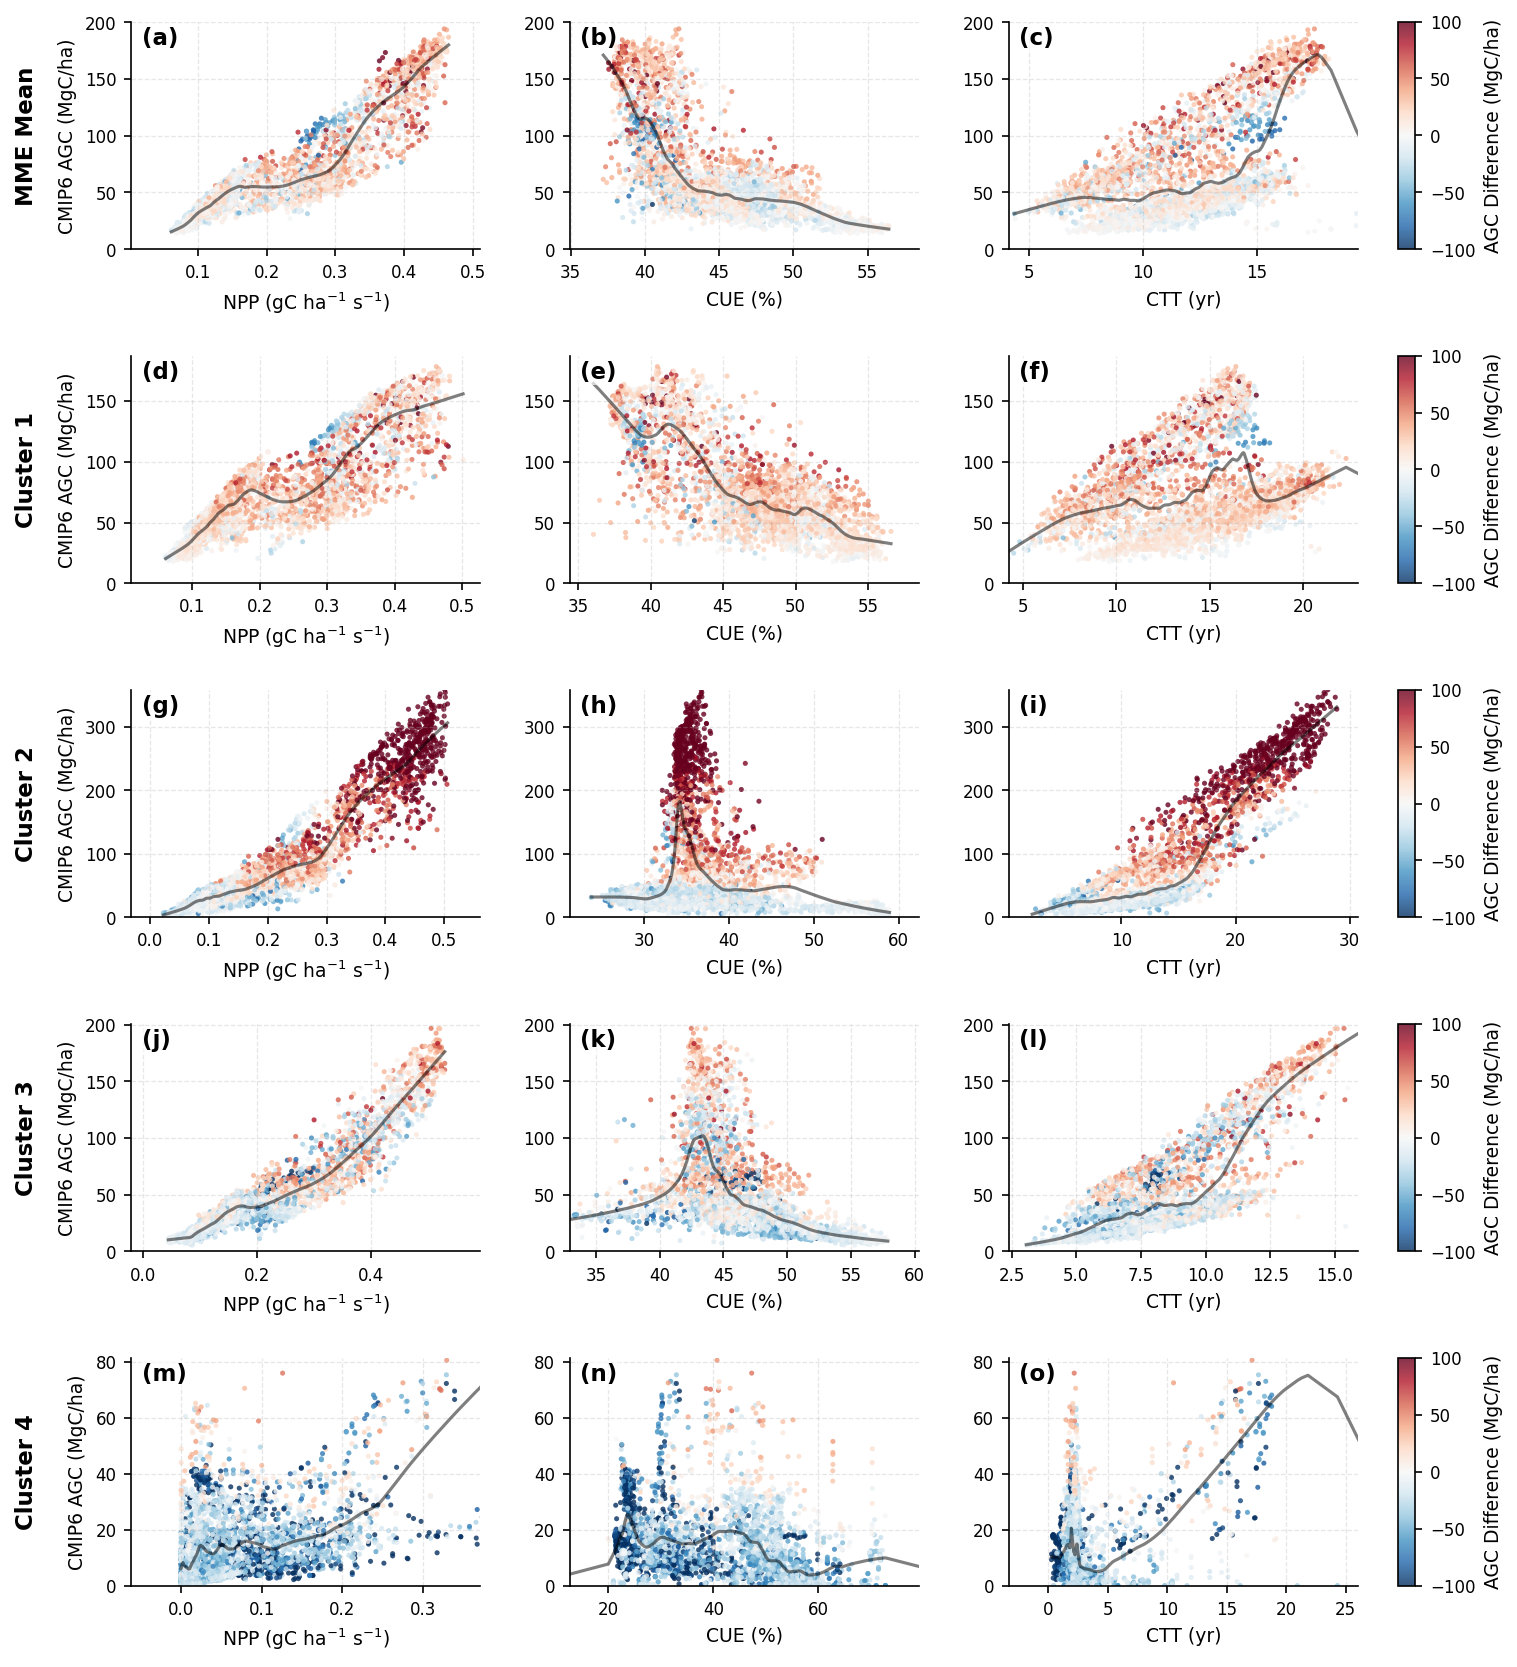

In [24]:
### ----- Plot ----- ###
metric_names = ["NPP", "CUE", "Turnover"]
metric_labels = [
    "NPP (gC ha$^{-1}$ s$^{-1}$)",
    "CUE (%)",
    "CTT (yr)",
]
plot_labels = list(cluster_results.keys())
letters = iter(ascii_lowercase)

fig = plt.figure(figsize=(10, 2.2*len(plot_labels)), dpi=150, constrained_layout=True)
gs = fig.add_gridspec(
    len(plot_labels), 4,
    width_ratios=[1.0, 1.0, 1.0, 0.05],
    wspace=0.1, hspace=0.1,
)

for row, label in enumerate(plot_labels):
    res = cluster_results[label]
    agc, diff = res["AGC"], res["diff"]
    color_lim = 100  # colorbar range
    scatter_for_cbar = None

    for col, (metric, xlabel) in enumerate(zip(metric_names, metric_labels)):
        ax = fig.add_subplot(gs[row, col])
        xmap = res["metrics"][metric]
        mask = TreeMask & np.isfinite(xmap) & np.isfinite(agc) & np.isfinite(diff)
        x_val, y_val, color = xmap[mask], agc[mask], diff[mask]
        if not (x_val.size > 10): continue

        # --- plot scatter ---
        scatter_for_cbar = ax.scatter(
            x_val, y_val, c=color, s=6, alpha=0.8, edgecolors="none",
            cmap="RdBu_r", vmin=-color_lim, vmax=color_lim,
        )
        # --- plot smooth line ---
        smooth = lowess(y_val, x_val, frac=0.1, it=1, return_sorted=True)
        ax.plot(smooth[:, 0], smooth[:, 1], color="black", linewidth=1.5, alpha=0.5)

        xlim = np.nanpercentile(x_val, [2, 98])
        if np.isfinite(xlim).all() and xlim[0] < xlim[1]:
            pad = (xlim[1] - xlim[0]) * 0.2
            ax.set_xlim(xlim[0]-pad, xlim[1]+pad)
        ylim = np.nanpercentile(y_val, [1, 99])
        if np.isfinite(ylim).all() and ylim[0] < ylim[1]:
            pad = (ylim[1] - ylim[0]) * 0.15
            ax.set_ylim(0, ylim[1]+pad)

        ax.grid(True, linestyle="--", linewidth=0.6, alpha=0.3)
        for spine in ["top", "right"]:
            ax.spines[spine].set_visible(False)
        ax.tick_params(labelsize=8)
        ax.set_xlabel(xlabel, fontsize=9)
        if col == 0:
            ax.set_ylabel("CMIP6 AGC (MgC/ha)", fontsize=9)
            ax.text(
                -0.3, 0.5, label,
                transform=ax.transAxes, rotation=90,
                ha="center", va="center", fontsize=11, fontweight="bold",
            )
        else:
            ax.set_ylabel("")
        panel_label(ax, next(letters))

    cax = fig.add_subplot(gs[row, 3])
    cbar = fig.colorbar(scatter_for_cbar, cax=cax)
    cbar.ax.tick_params(labelsize=8)
    cbar.set_label("AGC Difference (MgC/ha)", fontsize=9)

plt.show(fig)  # fig 8
plt.close(fig)
